In [34]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [35]:
class Time_point:
    def __init__(self, year:int, month:int, day:int, hour:int, minute:int):
        self.hour = hour
        self.minute = minute
        self.year = year
        self.month = month
        self.day = day
        self.date_str = f'{self.year:04d}-{self.month:02d}-{self.day:02d}'
        self.time_str = f'{self.hour:02d}:{self.minute:02d}'
        self.timepoint_str = f'{self.date_str} {self.time_str}'

    def timepoint_to_int(self): #in minutes
        return self.year*365*24*60 + self.month*30*24*60 + self.day*24*60 + self.hour*60 + self.minute

    def Time_Diffrence(self, other): #in hours
        return np.round(abs(self.timepoint_to_int() - other.timepoint_to_int())/60)

def int_to_timepoint(timepoint:int): #in minutes
    year =  timepoint//(365*24*60)
    month = (timepoint-year*365*24*60)//(30*24*60)
    day =   (timepoint-year*365*24*60-month*30*24*60)//(24*60)
    hour =  (timepoint-year*365*24*60-month*30*24*60-day*24*60)//60
    minute = (timepoint-year*365*24*60-month*30*24*60-day*24*60-hour*60)//1
    return Time_point(year,month,day,hour,minute)
    
def Time_add_duration(timepoint:Time_point, duration:int): #in hours
    return int_to_timepoint(timepoint.timepoint_to_int() + int(duration*60))


In [148]:
activity_type_list = ["Schlaf","Arbeit","Haushalt","Hobby","Fortbewegung","Sport","Entertainment","Sozial","Other"]
activity_dict      = {  "Schlafen":"Schlaf",
                      
                        "Programmieren":"Arbeit",
                        "Lernen":"Arbeit",

                        "Putzen":"Haushalt",
                        "Kochen":"Haushalt",

                        "Gärtnern":"Hobby",

                        "Bahnfahren":"Fortbewegung",

                        "Joggen":"Sport",
                        "Fahrrad Fahren":"Sport",

                        "Youtube":"Entertainment",
                        "Handy":"Entertainment",
                        "Serien schauen":"Entertainment",

                        "Telefonieren":"Sozial",
                        "Whatsapp":"Sozial",


                        }

valid_activity_names = ["Sport", "Putzen", "Bahnfahren", "Kochen", "Lernen", 
                        "Programmieren", "Gärtnern", "Youtube", "Handy", 
                        "Serien schauen","Fahrrad Fahren", "Telefonieren", "Whatsapp",  
                        "Joggen", "Schlafen"   
                        ]


In [43]:

class Activity:
    def __init__(self, name:str, start:Time_point, duration:float, passiv=False, activity_type:str = "Other"):
        self.name = name
        self.start = start
        self.duration = duration
        self.passiv = passiv
        self.activity_type = activity_type

        self.end = Time_add_duration(self.start,self.duration)

        self.start_str = start.timepoint_str
        self.end_str = self.end.timepoint_str

        self.start_date = start.date_str
        self.start_time = start.time_str
        self.end_date = self.end.date_str
        self.end_time = self.end.time_str


Act0 = Activity("Lernen",Time_point(2022, 1, 1, 11, 0), 2)

Act1 = Activity("Lernen",Time_point(2022, 1, 1, 11, 0), 2)

Act2 = Activity("Joggen",Time_point(2022, 1, 1, 18, 0), 3)
Act3 = Activity("Putzen",Time_point(2022, 1, 2, 11, 0), 1.5)
Act4 = Activity("Joggen", Time_point(2022, 1, 2, 13, 0), 1)
Act5 = Activity("Fahrrad Fahren", Time_point(2022, 1, 3, 15, 0), 4)

Act6 = Activity("Joggen", Time_point(2021, 1, 3, 15, 0), 4)

Act6 = Activity("Bahnfahren", Time_point(2022, 1, 3, 15, 0), 4,passiv=True)

print(Act0.name)
print(Act0.duration)
print(Act0.start_str)
print(Act0.end_str)



Lernen
2
2022-01-01 11:00
2022-01-01 13:00


In [144]:
Today = Time_point(2023, 1, 1, 12, 0)
today = Today.timepoint_to_int()

In [189]:

class ActivityList:
    def __init__(self):
        self.activities = []
        #self.activities.sort(key=lambda x: x.start)
        self.newest_activity = None
        self.oldest_activity = None
        self.total_duration = 0


    def add_new_activity(self, activity:Activity):
        if activity not in self.activities:
            if activity.passiv==True:
                self.activities.append(activity)
            else:
                if activity.name in valid_activity_names:    
                    if self.newest_activity == None:
                        self.activities.append(activity)
                        self.newest_activity = activity.end.timepoint_to_int()  
                        activity.activity_type = activity_dict[activity.name]
                        print('Activity succesfully added to list')
                    else:
                        if activity.start.timepoint_to_int() > self.newest_activity:                
                            self.activities.append(activity)   
                            self.newest_activity = activity.end.timepoint_to_int ()
                            activity.activity_type = activity_dict[activity.name]   
                            print('Activity succesfully added to list') 
                        else:
                            print('ERROR: this is not the newest activity \n use add_old_activity instead')
                else:
                    print('ERROR: this is not a valid activity')
        else:
            print("ERROR: Activity already in list")

    def print_activities(self):
        for activity in self.activities:
            print(f'Name:   {activity.name}')
            print(f'Dauer:  {np.round(activity.duration,2)}')
            print(f'Beginn: {activity.start_str}')
            print(f'Ende:   {activity.end_str}')
            if activity.passiv == True:
                print(f'Passiv: {activity.passiv}')
            print()

    def summarize_activitiy(self, name, start, end, printing=True):
        total_duration = 0
        for activity in self.activities:
            if activity.name == name:
                if activity.start.timepoint_to_int() >= start and activity.end.timepoint_to_int() <= end:
                    total_duration += activity.duration
        if printing == True:
            print(f'Name:   {name}')
            print(f'Dauer:  {np.round(total_duration,2)} Stunden')
            print()
        return total_duration

    def summarize_activitiy_alltime(self, name, printing=True):
        total_duration = 0
        for activity in self.activities:
            if activity.name == name:
                total_duration += activity.duration
        if printing == True:
            print(f'Name:   {name}')
            print(f'Dauer:  {np.round(total_duration,2)} Stunden')
            print()
        return total_duration

    def summarize_activitiy_type(self, type, start, end, printing=True):
        total_duration = 0
        for activity in self.activities:
            if activity.activity_type == type:
                if activity.start.timepoint_to_int() >= start and activity.end.timepoint_to_int() <= end:
                    total_duration += activity.duration
        if printing == True:
            print(f'Name:   {type}')
            print(f'Dauer:  {np.round(total_duration,2)} Stunden')
            print()
        return total_duration

    def summarize_activitiy_type_alltime(self, type, printing=True):
        total_duration = 0
        for activity in self.activities:
            if activity.activity_type == type:
                total_duration += activity.duration
        if printing == True:
            print(f'Name:   {type}')
            print(f'Dauer:  {np.round(total_duration,2)} Stunden')
            print()
        return total_duration
    

ActLst = ActivityList()

ActLst.add_new_activity(Act0)
ActLst.add_new_activity(Act0)
ActLst.add_new_activity(Act1)
ActLst.add_new_activity(Act2)
ActLst.add_new_activity(Act2)
ActLst.add_new_activity(Act3)
ActLst.add_new_activity(Act4)
ActLst.add_new_activity(Act5)
ActLst.add_new_activity(Act6)


for i in range(365):
    if np.random.randint(0,3)>=1:
        ActLst.add_new_activity(Activity("Joggen", int_to_timepoint(int(today-(365-i)*24*60 + 4*60 + 2.5*1*np.random.randn()*60)), 0.5*np.random.randint(0,4)))
    ActLst.add_new_activity(Activity("Schlafen", int_to_timepoint(int(today-(365-i)*24*60 + 10*60 + 1.5*1*np.random.randn()*60)), 8 + 1*np.random.randn()))



Activity succesfully added to list
ERROR: Activity already in list
ERROR: this is not the newest activity 
 use add_old_activity instead
Activity succesfully added to list
ERROR: Activity already in list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
ERROR: this is not the newest activity 
 use add_old_activity instead
ERROR: this is not the newest activity 
 use add_old_activity instead
ERROR: this is not the newest activity 
 use add_old_activity instead
ERROR: this is not the newest activity 
 use add_old_activity instead
ERROR: this is not the newest activity 
 use add_old_activity instead
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added to list
Activity succesfully added

In [190]:

ActLst.print_activities()


Name:   Lernen
Dauer:  2
Beginn: 2022-01-01 11:00
Ende:   2022-01-01 13:00

Name:   Joggen
Dauer:  3
Beginn: 2022-01-01 18:00
Ende:   2022-01-01 21:00

Name:   Putzen
Dauer:  1.5
Beginn: 2022-01-02 11:00
Ende:   2022-01-02 12:30

Name:   Joggen
Dauer:  1
Beginn: 2022-01-02 13:00
Ende:   2022-01-02 14:00

Name:   Fahrrad Fahren
Dauer:  4
Beginn: 2022-01-03 15:00
Ende:   2022-01-03 19:00

Name:   Bahnfahren
Dauer:  4
Beginn: 2022-01-03 15:00
Ende:   2022-01-03 19:00
Passiv: True

Name:   Schlafen
Dauer:  8.25
Beginn: 2022-01-03 23:16
Ende:   2022-01-04 07:30

Name:   Joggen
Dauer:  1.5
Beginn: 2022-01-04 21:01
Ende:   2022-01-04 22:31

Name:   Schlafen
Dauer:  8.67
Beginn: 2022-01-04 23:54
Ende:   2022-01-05 08:34

Name:   Joggen
Dauer:  1.5
Beginn: 2022-01-05 16:01
Ende:   2022-01-05 17:31

Name:   Schlafen
Dauer:  6.73
Beginn: 2022-01-05 22:33
Ende:   2022-01-06 05:16

Name:   Joggen
Dauer:  0.5
Beginn: 2022-01-06 15:41
Ende:   2022-01-06 16:11

Name:   Schlafen
Dauer:  9.85
Beginn: 20

In [191]:
ActLst.summarize_activitiy_alltime('Joggen')
ActLst.summarize_activitiy_type_alltime('Sport')
ActLst.summarize_activitiy_alltime('Schlafen')

Name:   Joggen
Dauer:  190.5 Stunden

Name:   Sport
Dauer:  194.5 Stunden

Name:   Schlafen
Dauer:  2857.06 Stunden



2857.06047914788

In [192]:

ActLst.summarize_activitiy('Joggen',today-365*24*60,today)


Name:   Joggen
Dauer:  190.5 Stunden



190.5

In [225]:
def recap_activity(name: str, List:ActivityList,length:int,bin_size:int,today): #Length and Binsize in days
    number_of_bins = length//bin_size
    data = []

    for i in range(number_of_bins):
        start=today - bin_size*(number_of_bins-(i))*24*60
        end=today - bin_size*(number_of_bins-(1+i))*24*60
        data.append(List.summarize_activitiy(name,start,end,printing=False))

    data = np.array(data)  
    x = np.arange(number_of_bins)

    plt.bar(x,data)
    plt.xlabel("Bin Zahl")
    plt.ylabel("Dauer [h]")
    plt.title(f'Recap der letzten {length} Tage')
    plt.text(0.75, 0.95,f'{bin_size} Tage pro Bin',
            transform=plt.gca().transAxes,verticalalignment='top')
    plt.xticks(x, [
        f'{i*bin_size}-{(i+1)*bin_size}'
        for i in range(number_of_bins)
        ], rotation=45)

    
    

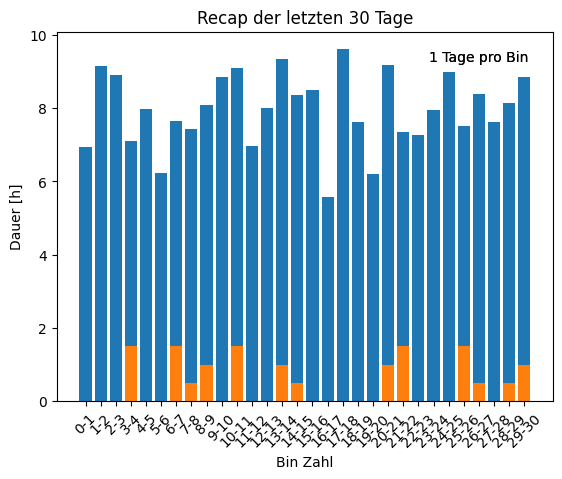

In [233]:
recap_activity('Schlafen',ActLst,30,1,today-30*24*60)
recap_activity('Joggen',ActLst,30,1,today-30*24*60)

In [260]:
def recap_activity(name: str, List:ActivityList,length:int,bin_size:int,today,smoothing_factor=5,smoothing=True): #Length and Binsize in days
    number_of_bins = length//bin_size
    data = []

    for i in range(number_of_bins+2*smoothing_factor):
        start=today+smoothing_factor - bin_size*(number_of_bins + smoothing_factor-(i))*24*60
        end=today+smoothing_factor - bin_size*(number_of_bins + smoothing_factor -(1+i))*24*60
        data.append(List.summarize_activitiy(name,start,end,printing=False))

    data = np.array(data)  
    data_plot = data[smoothing_factor:-smoothing_factor]
    x = np.arange(number_of_bins)
    data_smoothed = np.convolve(data,np.ones(smoothing_factor)/smoothing_factor,'same')

    plt.bar(x,data_plot)
    if smoothing == True:
        plt.plot(x,data_smoothed[smoothing_factor:-(smoothing_factor)],linestyle='-',marker='o',color='black')
    plt.xlabel("Bin Zahl")
    plt.ylabel("Dauer [h]")
    plt.title(f'Recap der letzten {length} Tage')
    plt.text(0.75, 0.95,f'{bin_size} Tage pro Bin',
            transform=plt.gca().transAxes,verticalalignment='top')
    plt.xticks(x, [
        f'{i*bin_size}-{(i+1)*bin_size}'
        for i in range(number_of_bins)
        ], rotation=45)

    
    

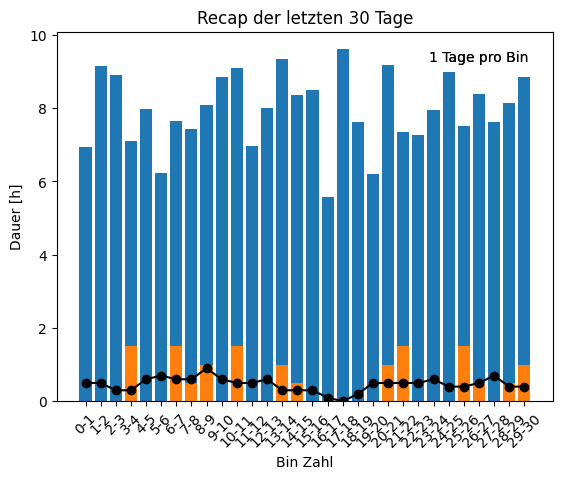

In [261]:
recap_activity('Schlafen',ActLst,30,1,today-30*24*60,smoothing=False)
recap_activity('Joggen',ActLst,30,1,today-30*24*60)

In [ ]:
import datetime
from datetime import datetime, timedelta
import numpy as np

class Abfrage:
    def __init__(self,Frage:str,Attribute:list):
        self.Frage = Frage
        self.Attribute = Attribute
        self.Anzahl = len(Attribute)

    def __str__(self):
        return f"Frage: {self.Frage} Attribute: {self.Attribute}"

    def __repr__(self):
        return f"Frage: {self.Frage} Attribute: {self.Attribute}"

Stimmung = Abfrage('Wie fühlst du dich heute?',['1','2','3','4','5','6','7','8','9','10'])
Energie = Abfrage('Wie viel Energie hattest du heute?',['1','2','3','4','5','6','7','8','9','10'])
Stress = Abfrage('Wie gestresst warst du heute?',['1','2','3','4','5','6','7','8','9','10'])

Sport = Abfrage('Wie lange hast du heute Sport gemacht?',['gar keinen','30min','1h','1.5h','2h+'])
Arbeit = Abfrage('Wie lange hast du heute produktiv gearbeitet?',['unter 4h','4-6h','6-8h','8-10h','10-12h'])
Schlaf = Abfrage('Wie lange hast du heute geschlafen?',['unter 4h','4-6h','6-8h','8-10h','10-12h'])
Sozial = Abfrage('Wie lange hast du dich heute Unterhalten?',['unter 30min','1h','2h','3h','4h+'])
Alkohol = Abfrage('Wie viel Alkohol hast du heute getrunken',['1Bier','2Bier','3Bier','4Bier','5Bier+'])
Youtube = Abfrage('Wie lange hast du heute Youtube geschaut?',['unter 30min','1h','2h','3h','4h+'])
Zocken = Abfrage('Wie lange hast du heute gezockt?',['0h','1h','2h','3h','4h+'])
Serien = Abfrage('Wie viele Serien hast du heute geschaut?',['0 Folgen','1 Folge','2 Folgen','3 Folgen','4+ Folgen'])

Erste_Abfrage_Liste = [Stimmung,Energie,Stress,
                 Schlaf,Arbeit,Sport,Sozial,Alkohol,Youtube,Zocken,Serien]


[Frage: Wie fühlst du dich heute? Attribute: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10'], Frage: Wie viel Energie hattest du heute? Attribute: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10'], Frage: Wie gestresst warst du heute? Attribute: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10'], Frage: Wie lange hast du heute geschlafen? Attribute: ['unter 4h', '4-6h', '6-8h', '8-10h', '10-12h'], Frage: Wie lange hast du heute produktiv gearbeitet? Attribute: ['unter 4h', '4-6h', '6-8h', '8-10h', '10-12h'], Frage: Wie lange hast du heute Sport gemacht? Attribute: ['gar keinen', '30min', '1h', '1.5h', '2h+'], Frage: Wie lange hast du dich heute Unterhalten? Attribute: ['unter 30min', '1h', '2h', '3h', '4h+'], Frage: Wie viel Alkohol hast du heute getrunken Attribute: ['1Bier', '2Bier', '3Bier', '4Bier', '5Bier+'], Frage: Wie lange hast du heute Youtube geschaut? Attribute: ['unter 30min', '1h', '2h', '3h', '4h+'], Frage: Wie lange hast du heute gezockt? Attribute: ['0h', '1h', '

In [ ]:
List_of_daily_Recaps = []
Antwort_Array = []

In [ ]:

class Daily_Recap:
    def __init__(self,Datum,Antworten:np.array):
        self.Datum = Datum
        self.Antworten = Antworten

    def __str__(self):
        return 'Datum: ' + str(self.Datum) + '\n' + 'Antworten:' + str(self.Antworten)

def Daily_Abfrage(Recap_Liste:list[Daily_Recap],Ant_Array:np.array):
    print('Tägliche abfrage')
    Datum = datetime.today()
    print('Datum:' , datetime.today().date())
    New_Recap = Daily_Recap(Datum,np.array([]))
    for Abfrage in Erste_Abfrage_Liste:
        print(Abfrage)
        Antwort = 0
        while Antwort not in np.arange(1,Abfrage.Anzahl+1):
            Antwort = int(input(Abfrage))
        Antwort = Antwort - 1 
        print(Abfrage.Attribute[Antwort])
        New_Recap.Antworten = np.append(New_Recap.Antworten,Antwort)
    Ant_Array.append(New_Recap.Antworten)
    Recap_Liste.append(New_Recap)


In [130]:
def print_daily_recaps(Recap_Liste,Abfrage_Liste):
    for recap in Recap_Liste:
        print(recap.Datum)
        # for Abfrage in Abfrage_Liste:
        #     print(Abfrage.Frage+' '+Abfrage.Attribute[recap.Antworten[i]])
        i=0
        for i in range(len(Abfrage_Liste)):
            print(Abfrage_Liste[i].Frage+' '+Abfrage_Liste[i].Attribute[int(recap.Antworten[i])])
        print('')


In [126]:
Daily_Abfrage(List_of_daily_Recaps,Antwort_Array)

Tägliche abfrage
Datum: 2026-09-28
Frage: Wie fühlst du dich heute? Attribute: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
5
Frage: Wie viel Energie hattest du heute? Attribute: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
2
Frage: Wie gestresst warst du heute? Attribute: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
5
Frage: Wie lange hast du heute geschlafen? Attribute: ['unter 4h', '4-6h', '6-8h', '8-10h', '10-12h']
4-6h
Frage: Wie lange hast du heute produktiv gearbeitet? Attribute: ['unter 4h', '4-6h', '6-8h', '8-10h', '10-12h']
10-12h
Frage: Wie lange hast du heute Sport gemacht? Attribute: ['gar keinen', '30min', '1h', '1.5h', '2h+']
30min
Frage: Wie lange hast du dich heute Unterhalten? Attribute: ['unter 30min', '1h', '2h', '3h', '4h+']
4h+
Frage: Wie viel Alkohol hast du heute getrunken Attribute: ['1Bier', '2Bier', '3Bier', '4Bier', '5Bier+']
2Bier
Frage: Wie lange hast du heute Youtube geschaut? Attribute: ['unter 30min', '1h', '2h', '3h', '4h+']
4h+
Fr

In [ ]:
for recap in List_of_daily_Recaps:
    print(recap)

Datum: 2026-09-28 20:48:29.696522
Antworten:[9. 0. 0. 3. 4. 4. 0. 0. 0. 0. 0.]
Datum: 2026-09-28 20:49:07.978759
Antworten:[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Datum: 2026-09-28 20:49:16.059889
Antworten:[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Datum: 2026-09-28 20:49:23.682174
Antworten:[2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
Datum: 2026-09-28 21:01:08.949901
Antworten:[3. 3. 3. 3. 3. 3. 3. 3. 3. 3. 3.]
Datum: 2026-09-28 21:01:17.026129
Antworten:[1. 2. 1. 2. 1. 2. 1. 2. 1. 2. 1.]
Datum: 2026-09-28 21:01:26.845311
Antworten:[4. 1. 4. 1. 4. 1. 4. 1. 4. 1. 4.]


In [ ]:

print_daily_recaps(List_of_daily_Recaps,Erste_Abfrage_Liste)

In [128]:
import numpy as np

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Daten
Data = np.array(Antwort_Array)
X = Data[:, 3:]
Y = Data[:, :3]

# Train-Test-Split
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

# Pipeline:
# Standardisierung + Ridge Regression
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Werte für den Regularisierungsparameter
param_grid = {
    "ridge__alpha": np.logspace(-4, 4, 50)
}

# K-Fold Cross Validation
kf = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=kf,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Training + Cross Validation
grid_search.fit(X_train, Y_train)

# Bestes Modell
model = grid_search.best_estimator_

print("Bestes alpha:", grid_search.best_params_["ridge__alpha"])

# Testdaten
Y_pred = model.predict(X_test)

# Evaluation
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R²:", r2)

for i, name in enumerate(["Stimmung", "Energie", "Stress"]):
    rmse = np.sqrt(mean_squared_error(Y_test[:, i], Y_pred[:, i]))
    r2 = r2_score(Y_test[:, i], Y_pred[:, i])

    print(f"{name}:")
    print(f"  RMSE = {rmse:.3f}")
    print(f"  R²   = {r2:.3f}")

Bestes alpha: 0.0001
Test MSE: 11.343736055393967
Test RMSE: 3.368046326194752
Test R²: -0.19341484843485057
Stimmung:
  RMSE = 5.657
  R²   = -0.580
Energie:
  RMSE = 1.237
  R²   = 0.000
Stress:
  RMSE = 0.707
  R²   = 0.000
